# Serie I · Campo — 04. Segmentación de variedades

**Pregunta 3 de la prueba:** segmentar las variedades según su comportamiento (productividad, calidad, longevidad y
estabilidad entre localidades y años) y explicar qué representa cada grupo para la Gerencia.

**Qué variedades.** Las 23 con evidencia suficiente de la pregunta 1 (D15: ≥ 2 años en etapa 5, plantía medida y socas
hasta la soca 2). Las otras 17 no se pueden segmentar con honestidad: 13 solo tienen un año de plantía (no hay
longevidad ni estabilidad que medir), 3 son antiguas sin plantía en 2010-2021 y una no llegó a soca 2.

**Método, en una línea por paso**
1. Cuatro indicadores por variedad, todos **contra los testigos núcleo del mismo ensayo y corte** (como en P1 y P2).
2. ¿Hay grupos naturales? Se compara la separación de los grupos contra datos sin estructura.
3. Número de grupos por **estabilidad**: se repite todo remuestreando ensayos y se ve qué tan reproducibles son.
4. Perfil de cada grupo, certeza de cada asignación y validación externa con el margen de la pregunta 1 (que no se usó
   para formar los grupos).

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from campo_data import load_raw, clean
from campo_economia import CORE_CHECKS
from campo_segmentos import preparar, indicadores, estandarizar, nombrar, INDICADORES

FIG = ROOT / "outputs" / "figures"; TAB = ROOT / "outputs" / "tables"; MOD = ROOT / "outputs" / "models"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9993"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
})
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / nombre, bbox_inches="tight"); plt.show()
pct = lambda v: f"{np.exp(v) - 1:+.1%}"
SEED = 20261019

In [2]:
df, _ = clean(load_raw(ROOT / "data" / "raw" / "All_Genotypes_2010_onwards.csv"))
P = preparar(df[df["STAGE"] == 5])
REC = pd.read_csv(TAB / "serie1_recomendacion.csv", index_col=0)      # salida de la pregunta 1
ELEGIBLES = REC.index.tolist()
print(f"{len(ELEGIBLES)} variedades con evidencia suficiente; {P['TRIAL'].nunique()} ensayos de etapa 5, {len(P):,} parcelas")

23 variedades con evidencia suficiente; 160 ensayos de etapa 5, 4,708 parcelas


## 1. Cuatro indicadores, todos contra los testigos

| Indicador | Cómo se mide | En el ingenio se diría |
|---|---|---|
| **Productividad** | caña por acre (TCA) en plantía, contra los testigos del mismo ensayo y corte | TCH |
| **Calidad** | azúcar recuperable por tonelada (TRS), contra los testigos, promedio de todos los cortes | rendimiento (kg/t) |
| **Longevidad** | cuánto gana o pierde la variedad en caña **por cada corte**, contra los testigos | persistencia de la cepa |
| **Estabilidad** | variación de su ventaja entre fincas y años que **no** explica la calidad de la finca, **sin el ruido de parcela** | qué tan predecible es |

Tres decisiones:
- **Caña y calidad por separado, no azúcar y calidad.** Azúcar = caña × calidad: si se usan azúcar y calidad, la calidad
  cuenta dos veces. El azúcar se reconstruye después.
- **Longevidad en caña.** Es la cepa la que rebrota. Medida en azúcar da casi lo mismo (se verifica abajo).
- **Estabilidad a la Eberhart y Russell, con dos correcciones.** Primero se quita la parte que se explica por la calidad
  de la finca (la *respuesta* al ambiente, medida con un índice **independiente**: la trampa H3 de la pregunta 1). Lo que
  queda incluye el ruido de la parcela (repeticiones) y del promedio de testigos; ese ruido se mide con las repeticiones
  y se resta. Si no se resta, las variedades con menos repeticiones parecen menos estables sin serlo.

In [3]:
X = indicadores(P, ELEGIBLES)
assert len(X) == len(ELEGIBLES)
tabla = (np.exp(X[INDICADORES + ["respuesta"]]) - 1).mul(100).round(1)
tabla["estabilidad"] = (-X["estabilidad"] * 100).round(1)            # σ en %: menor = más estable
tabla = tabla.rename(columns={"productividad": "caña vs testigos %", "calidad": "TRS vs testigos %",
                              "longevidad": "caña por corte vs testigos %", "estabilidad": "σ interacción %",
                              "respuesta": "respuesta al ambiente"}).join(X[["parcelas", "anios", "ultimo_corte"]].astype(int))
display(tabla.sort_values("caña vs testigos %", ascending=False))

ruido = (X["sd_ruido"]**2 / X["sd_bruta"]**2)
print(f"Del desvío bruto de la ventaja, el ruido de parcela es en mediana {ruido.median():.0%} de la varianza "
      f"(rango {ruido.min():.0%}-{ruido.max():.0%}).")
# Longevidad en caña vs en azúcar
lon_az = {c: np.polyfit(g["CROP"], g["l_s"], 1)[0] for c, g in P[P["CLONE"].isin(ELEGIBLES) & P["l_s"].notna()].groupby("CLONE")}
print(f"Correlación longevidad en caña vs en azúcar: {np.corrcoef(X['longevidad'], pd.Series(lon_az)[X.index])[0, 1]:.2f}")

,caña vs testigos %,TRS vs testigos %,caña por corte vs testigos %,σ interacción %,respuesta al ambiente,parcelas,anios,ultimo_corte
HO11-573,14.4,-2.4,-7.8,6.3,6.3,43,3,4
HO12-615,12.9,-0.8,-0.5,5.1,-7.5,178,6,4
HOCP14-885,9.9,7.5,1.7,8.5,10.2,100,4,3
L09-112,8.9,-7.8,-1.5,5.7,5.3,29,2,3
HO12-630,4.0,2.0,-4.4,6.9,-1.8,59,3,2
L15-306,2.3,5.0,6.5,2.3,-15.4,60,3,2
HO07-613,2.1,3.9,-9.4,15.7,-14.5,234,10,4
L11-183,2.0,-0.9,-2.2,6.2,-0.3,209,7,4
L14-267,1.7,5.6,3.5,3.3,-9.7,100,4,3
HOCP04-838,1.3,0.2,-2.5,9.2,16.2,424,12,4


Del desvío bruto de la ventaja, el ruido de parcela es en mediana 67% de la varianza (rango 30%-96%).
Correlación longevidad en caña vs en azúcar: 0.99


**Lectura.** El ruido de parcela es la mayor parte de la varianza bruta: sin restarlo, la "estabilidad" sería sobre todo
una medida de cuántas repeticiones tuvo cada variedad. Restado, quedan diferencias reales: HOCP96-540 y HO07-613 varían
2-3 veces más que el resto.

In [4]:
r = X[INDICADORES].corr()
p = pd.DataFrame([[stats.pearsonr(X[a], X[b])[1] for b in INDICADORES] for a in INDICADORES], index=INDICADORES, columns=INDICADORES)
display(r.round(2).astype(str) + p.map(lambda v: " *" if v < 0.05 else ""))
print("* p < 0.05 (n = 23)")

,productividad,calidad,longevidad,estabilidad
productividad,1.0 *,-0.44 *,-0.25,0.2
calidad,-0.44 *,1.0 *,0.48 *,0.16
longevidad,-0.25,0.48 *,1.0 *,0.58 *
estabilidad,0.2,0.16,0.58 *,1.0 *


* p < 0.05 (n = 23)


**Lectura: hay compromisos.** Las variedades de más caña tienden a tener menos calidad (r = −0.44 con estas 23 variedades y la caña de
plantía; con todos los clones de etapa 5 y todos los cortes casi desaparece, notebook 01) y las de más
calidad tienden a durar más. Las más longevas también son más estables. No existe la variedad que gane en todo; los
grupos van a reflejar esos compromisos.

## 2. ¿Hay grupos naturales?

Un algoritmo de agrupamiento siempre devuelve grupos, aunque los datos no los tengan. Prueba: la separación de los
grupos (silueta) se compara contra la de 200 tablas sin estructura, en las que cada indicador se baraja por separado
(mismas distribuciones, sin relación entre indicadores ni variedades).

In [5]:
Z, MU, SD = estandarizar(X)
KS = list(range(2, 8))
obs = {k: silhouette_score(Z, KMeans(k, n_init=50, random_state=SEED).fit_predict(Z)) for k in KS}
rng = np.random.default_rng(SEED)
nulo = {k: [] for k in KS}
for _ in range(200):
    Zp = Z.apply(lambda col: rng.permutation(col.to_numpy()))
    for k in KS:
        nulo[k].append(silhouette_score(Zp, KMeans(k, n_init=10, random_state=SEED).fit_predict(Zp)))
SIL = pd.DataFrame({"silueta": obs, "nulo_p50": {k: np.median(v) for k, v in nulo.items()},
                    "nulo_p95": {k: np.percentile(v, 95) for k, v in nulo.items()},
                    "p": {k: np.mean(np.array(nulo[k]) >= obs[k]) for k in KS}})
display(SIL.round(3))
pca = PCA().fit(Z)
print("Varianza por componente principal:", (pca.explained_variance_ratio_ * 100).round(0), "%")
display(pd.DataFrame(pca.components_[:2], columns=INDICADORES, index=["CP1", "CP2"]).round(2))

,silueta,nulo_p50,nulo_p95,p
2,0.288,0.232,0.374,0.190
3,0.301,0.236,0.315,0.065
4,0.251,0.253,0.320,0.520
5,0.280,0.258,0.335,0.315
6,0.285,0.255,0.331,0.240
7,0.256,0.252,0.330,0.455


Varianza por componente principal: [48. 33. 12.  7.] %


,productividad,calidad,longevidad,estabilidad
CP1,-0.34,0.56,0.63,0.42
CP2,0.67,-0.30,0.20,0.64


**Lectura.** Ninguna partición separa las variedades mejor que tablas sin estructura (p > 0.05 para todo k). Las 23
variedades forman un **continuo**, no tipos naturales. Dos ejes resumen ~80 % de la variación: el primero opone
*calidad + longevidad + estabilidad* a *tonelaje*; el segundo es *tonelaje + estabilidad*.

**Decisión (D29).** Se segmenta igual, porque la Gerencia necesita hablar de perfiles y no de 23 casos, pero se presenta
como lo que es: **una forma útil de partir un continuo**. Por eso importan dos cosas más que el algoritmo: que la
partición sea **reproducible** (sección 3) y que cada asignación diga **qué tan firme es** (sección 5).

## 3. Cuántos grupos: los que se reproducen

Se remuestrean **ensayos completos** (300 veces), se recalculan los 4 indicadores y se vuelve a agrupar. El índice de
Rand ajustado (ARI) mide cuánto se parece cada partición remuestreada a la original (1 = idéntica, 0 = al azar).

**Regla (fijada después de explorar, ver bitácora):** entre 3 y 7 grupos, el más reproducible que no deje grupos de una
sola variedad. Con 2 grupos la partición es la más estable, pero no sirve para decidir: solo separa tonelaje de calidad.

El algoritmo es k-means sobre los indicadores estandarizados; Ward (jerárquico) se usa como contraste.

In [6]:
REF = {k: KMeans(k, n_init=100, random_state=SEED).fit(Z) for k in KS}
ensayos = P["TRIAL"].unique()
por_ensayo = {t: g for t, g in P.groupby("TRIAL")}
B = 300
ARI = {k: [] for k in KS}
BOOT_LAB, BOOT_OK = [], []
t0 = time.time()
rng = np.random.default_rng(SEED)
for b in range(B):
    Pb = pd.concat([por_ensayo[t] for t in rng.choice(ensayos, size=len(ensayos), replace=True)])
    Xb = indicadores(Pb, ELEGIBLES).reindex(X.index)
    ok = Xb[INDICADORES].notna().all(axis=1).to_numpy()
    Zb = (Xb.loc[ok, INDICADORES] - Xb.loc[ok, INDICADORES].mean()) / Xb.loc[ok, INDICADORES].std()
    labs = {}
    for k in KS:
        labs[k] = KMeans(k, n_init=10, random_state=SEED).fit_predict(Zb)
        ARI[k].append(adjusted_rand_score(REF[k].labels_[ok], labs[k]))
    BOOT_LAB.append(labs); BOOT_OK.append(ok)
print(f"{B} réplicas en {time.time() - t0:.0f} s")
ESTAB = pd.DataFrame({"ARI_mediana": {k: np.median(v) for k, v in ARI.items()},
                      "ARI_p10": {k: np.percentile(v, 10) for k, v in ARI.items()},
                      "ARI_p90": {k: np.percentile(v, 90) for k, v in ARI.items()},
                      "ward_vs_kmeans": {k: adjusted_rand_score(REF[k].labels_, AgglomerativeClustering(k, linkage="ward").fit_predict(Z)) for k in KS},
                      "tamaños": {k: sorted(np.bincount(REF[k].labels_), reverse=True) for k in KS}})
display(ESTAB.round(2))
candidatos = [k for k in KS if k > 2 and min(ESTAB.loc[k, "tamaños"]) >= 2]
K = max(candidatos, key=lambda k: ESTAB.loc[k, "ARI_mediana"])
print(f"Grupos elegidos: K = {K} (reproducibilidad mediana {ESTAB.loc[K, 'ARI_mediana']:.2f}; "
      f"Ward coincide con k-means en ARI = {ESTAB.loc[K, 'ward_vs_kmeans']:.2f})")

300 réplicas en 59 s


,ARI_mediana,ARI_p10,ARI_p90,ward_vs_kmeans,tamaños
2,0.91,0.67,1.00,0.53,"[14, 9]"
3,0.58,0.23,1.00,0.58,"[14, 7, 2]"
4,0.44,0.23,0.65,0.63,"[9, 7, 5, 2]"
5,0.62,0.36,0.88,0.76,"[7, 6, 5, 3, 2]"
6,0.60,0.36,0.83,0.70,"[7, 5, 5, 3, 2, 1]"
7,0.57,0.36,0.79,0.73,"[7, 5, 5, 3, 1, 1, 1]"


Grupos elegidos: K = 5 (reproducibilidad mediana 0.62; Ward coincide con k-means en ARI = 0.76)


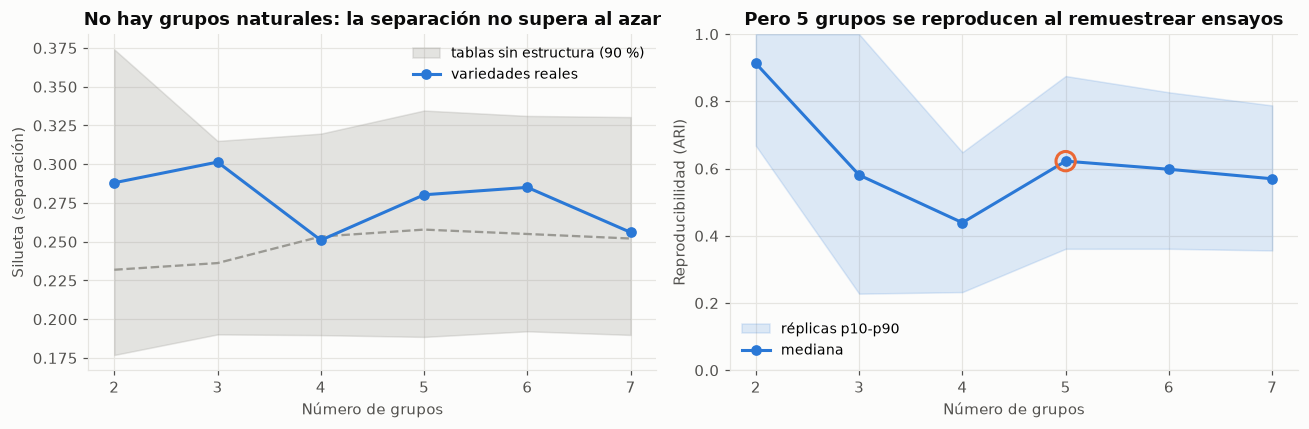

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.fill_between(KS, [np.percentile(nulo[k], 5) for k in KS], SIL["nulo_p95"], color=GRIS, alpha=0.25, label="tablas sin estructura (90 %)")
ax.plot(KS, SIL["nulo_p50"], color=GRIS, lw=1.5, ls="--")
ax.plot(KS, SIL["silueta"], color=AZUL, marker="o", label="variedades reales")
ax.set_xlabel("Número de grupos"); ax.set_ylabel("Silueta (separación)")
ax.set_title("No hay grupos naturales: la separación no supera al azar"); ax.legend(frameon=False, fontsize=9)
ax = axes[1]
ax.fill_between(KS, ESTAB["ARI_p10"], ESTAB["ARI_p90"], color=AZUL, alpha=0.15, label="réplicas p10-p90")
ax.plot(KS, ESTAB["ARI_mediana"], color=AZUL, marker="o", label="mediana")
ax.scatter([K], [ESTAB.loc[K, "ARI_mediana"]], s=160, facecolor="none", edgecolor=NARANJA, lw=2, zorder=3)
ax.set_xlabel("Número de grupos"); ax.set_ylabel("Reproducibilidad (ARI)"); ax.set_ylim(0, 1)
ax.set_title(f"Pero {K} grupos se reproducen al remuestrear ensayos"); ax.legend(frameon=False, fontsize=9, loc="lower left")
guardar(fig, "serie1_19_cuantos_grupos.png")

## 4. Los grupos y su perfil

Los nombres se asignan con reglas fijas sobre el centro de cada grupo (código en `campo_segmentos.nombrar`), en este
orden: el menos estable, el de mejor suma caña + calidad + longevidad, el de más caña frente a calidad, el de más
calidad frente a caña; el que queda es "sin ventaja clara".

In [8]:
km = REF[K]
CEN = pd.DataFrame(km.cluster_centers_, columns=INDICADORES)
NOMBRES = nombrar(CEN)
ORDEN_G = ["Completas: caña, calidad y longevidad", "Calidad sin caña", "Mucha caña, menos calidad",
           "Inestables y de vida corta", "Sin ventaja clara"]
ORDEN_G = [g for g in ORDEN_G if g in NOMBRES.values()]
COLOR = dict(zip(["Completas: caña, calidad y longevidad", "Calidad sin caña", "Mucha caña, menos calidad",
                  "Inestables y de vida corta", "Sin ventaja clara"], [AZUL, NARANJA, AQUA, AMARILLO, GRIS]))
SEG = X.copy()
SEG["grupo"] = pd.Series(km.labels_, index=X.index).map(NOMBRES)
SEG["ganancia_p1"] = REC["ganancia_vs_testigos"]; SEG["rank_p1"] = REC["rank"]; SEG["ciclo_p1"] = REC["ciclo_optimo"]
fib = P[P["CLONE"].isin(ELEGIBLES)].groupby("CLONE")["dif_fibra"].agg(["mean", "count"])
SEG["fibra_dif_pp"] = fib["mean"].where(fib["count"] >= 20); SEG["fibra_parcelas"] = fib["count"]

def perfil(g):
    return pd.Series({
        "variedades": len(g), "caña %": (np.exp(g["productividad"].mean()) - 1) * 100,
        "TRS %": (np.exp(g["calidad"].mean()) - 1) * 100,
        "azúcar plantía %": (np.exp(g["productividad"].mean() + g["calidad"].mean()) - 1) * 100,
        "caña por corte %": (np.exp(g["longevidad"].mean()) - 1) * 100, "σ interacción %": -g["estabilidad"].mean() * 100,
        "respuesta": round(g["respuesta"].mean(), 2), "fibra pp": g["fibra_dif_pp"].mean(),
        "con fibra medida": int(g["fibra_dif_pp"].notna().sum()),
        "ganancia P1 US$/acre/año (mediana)": g["ganancia_p1"].median(),
        "años de evidencia (mediana)": g["anios"].median()})
PERFIL = SEG.groupby("grupo").apply(perfil, include_groups=False).loc[ORDEN_G]
display(PERFIL.round(1).assign(respuesta=PERFIL["respuesta"].round(2)))
for g in ORDEN_G:
    m = SEG[SEG["grupo"] == g].sort_values("rank_p1")
    print(f"{g}: " + ", ".join(f"{c}{' (testigo)' if c in CORE_CHECKS else ''}" for c in m.index))

,variedades,caña %,TRS %,azúcar plantía %,caña por corte %,σ interacción %,respuesta,fibra pp,con fibra medida,ganancia P1 US$/acre/año (mediana),años de evidencia (mediana)
grupo,,,,,,,,,,,
"Completas: caña, calidad y longevidad",6.0,1.7,5.6,7.5,5.0,5.4,-0.06,0.2,6.0,191.1,4.0
Calidad sin caña,5.0,-4.7,5.1,0.1,0.7,9.5,-0.02,0.3,3.0,7.5,9.0
"Mucha caña, menos calidad",3.0,12.0,-3.7,7.9,-3.3,5.7,0.01,0.9,1.0,9.4,3.0
Inestables y de vida corta,2.0,1.4,-0.9,0.6,-8.9,17.2,-0.17,-1.1,1.0,-114.8,11.0
Sin ventaja clara,7.0,0.7,0.3,1.0,-1.8,6.9,-0.01,-0.2,3.0,-22.6,6.0


Completas: caña, calidad y longevidad: HOCP14-885, HOL15-508, L15-306, L14-267, L01-299 (testigo), HO13-739
Calidad sin caña: HOCP09-804, L01-283 (testigo), L03-371, HOCP00-950, HO05-961
Mucha caña, menos calidad: HO12-615, HO11-573, L09-112
Inestables y de vida corta: HO07-613, HOCP96-540 (testigo)
Sin ventaja clara: L12-201, L99-226, HO12-630, HOCP04-838 (testigo), L11-183, HO09-840, L99-233


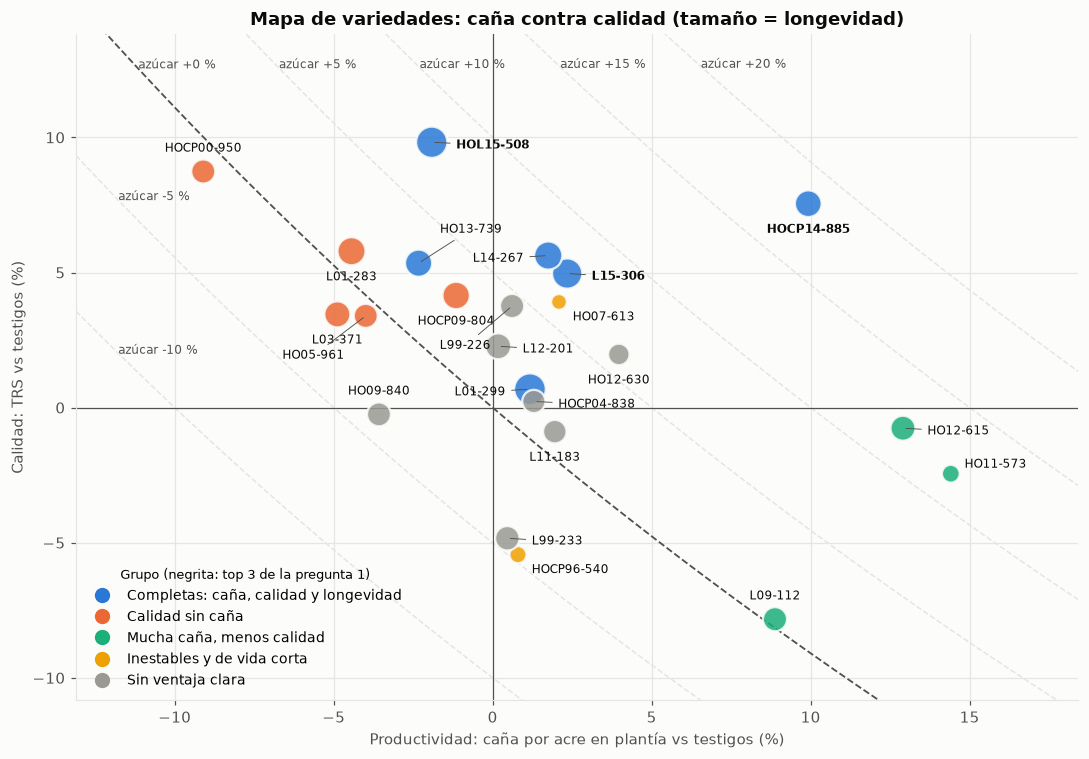

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
xv, yv = (np.exp(X["productividad"]) - 1) * 100, (np.exp(X["calidad"]) - 1) * 100
# curvas de igual azúcar en plantía (caña × calidad)
x0, x1, y0, y1 = xv.min() - 4, xv.max() + 4, yv.min() - 3, yv.max() + 4
xs = np.linspace(x0, x1, 400)
for s in [-10, -5, 0, 5, 10, 15, 20]:
    ys = ((1 + s / 100) / (1 + xs / 100) - 1) * 100
    ax.plot(xs, ys, color=REJILLA if s else TINTA2, lw=1 if s else 1.2, ls="--", zorder=1)
    dentro = (ys > y0) & (ys < y1 - 0.8) & (xs > x0 + 1) & (xs < x1 - 1)
    if dentro.any():                                    # etiqueta en el punto más alto visible de la curva
        i = np.where(dentro)[0][0]
        ax.text(xs[i] + 0.3, ys[i], f"azúcar {s:+d} %", fontsize=8, color=TINTA2, ha="left", va="top")
for g in ORDEN_G:
    m = SEG["grupo"] == g
    size = 60 + 1800 * np.clip(np.exp(X.loc[m, "longevidad"]) - 0.88, 0.01, None)
    ax.scatter(xv[m], yv[m], s=size, color=COLOR[g], alpha=0.85, edgecolor="#fcfcfb", lw=1.5, label=g, zorder=3)
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
# Etiquetas sin choques: se prueban 8 posiciones alrededor de cada punto (en píxeles) y se elige la primera que no pisa
# otra etiqueta ni otro punto; si ninguna sirve, se usa la menos mala con una línea guía.
PX = fig.dpi / 72
tamaño = {c: 60 + 1800 * np.clip(np.exp(X.loc[c, "longevidad"]) - 0.88, 0.01, None) for c in X.index}
pts = {c: ax.transData.transform((xv[c], yv[c])) for c in X.index}
radio = {c: np.sqrt(tamaño[c] / np.pi) * PX + 2 for c in X.index}
cands = [(9, 6), (9, -10), (-9, 6), (-9, -10), (0, 15), (0, -17), (16, -2), (-16, -2), (14, 22), (-14, -26)]
puestas = []
def caja(c, dx, dy):
    w, h = 6.6 * len(c) * PX * 0.8, 9.5 * PX
    x, y = pts[c][0] + dx * PX, pts[c][1] + dy * PX
    x0_ = x if dx > 0 else (x - w if dx < 0 else x - w / 2)
    return (x0_, y - h / 2, x0_ + w, y + h / 2)
def choque(b, c):
    n = sum(not (b[2] < q[0] or b[0] > q[2] or b[3] < q[1] or b[1] > q[3]) for q in puestas)
    for o in X.index:
        px, py = pts[o]; r = radio[o]
        if b[0] - r < px < b[2] + r and b[1] - r < py < b[3] + r: n += 1
    return n
for c in X.sort_values("calidad", ascending=False).index:
    puntajes = [(choque(caja(c, dx, dy), c), i) for i, (dx, dy) in enumerate(cands)]
    mejor = min(puntajes)[1]; dx, dy = cands[mejor]
    puestas.append(caja(c, dx, dy))
    ax.annotate(c, (xv[c], yv[c]), xytext=(dx, dy), textcoords="offset points", fontsize=8, color=TINTA,
                ha="left" if dx > 0 else ("right" if dx < 0 else "center"), va="center",
                fontweight="bold" if c in REC.index[:3] else "normal",
                arrowprops=dict(arrowstyle="-", color=TINTA2, lw=0.6) if mejor >= 6 else None)
ax.axhline(0, color=TINTA2, lw=0.8); ax.axvline(0, color=TINTA2, lw=0.8)
ax.set_xlabel("Productividad: caña por acre en plantía vs testigos (%)"); ax.set_ylabel("Calidad: TRS vs testigos (%)")
ax.set_title("Mapa de variedades: caña contra calidad (tamaño = longevidad)")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", markersize=9, color=COLOR[g], label=g) for g in ORDEN_G],
          frameon=False, fontsize=9, loc="lower left", title="Grupo (negrita: top 3 de la pregunta 1)", title_fontsize=8.5)
guardar(fig, "serie1_20_mapa_variedades.png")

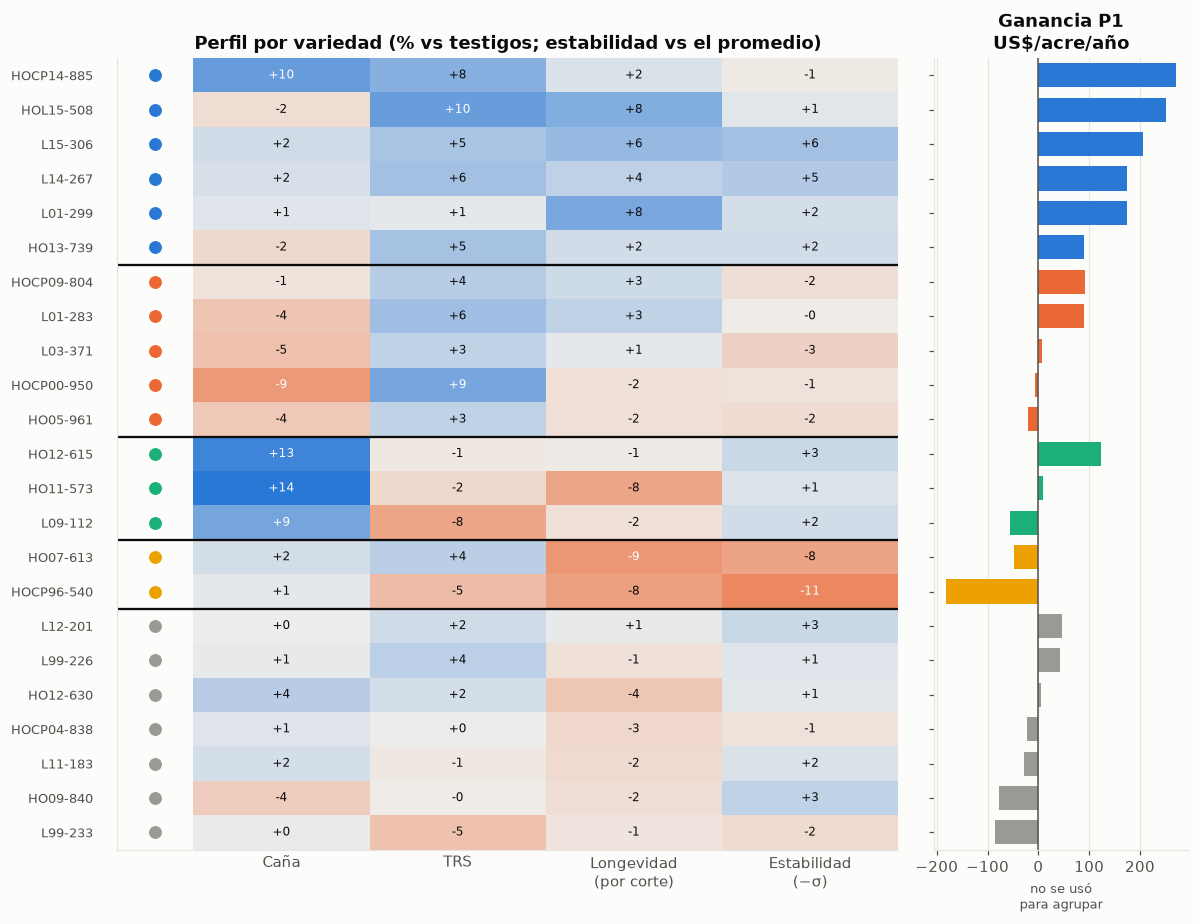

In [10]:
orden = SEG.sort_values(["grupo", "rank_p1"], key=lambda s: s.map({g: i for i, g in enumerate(ORDEN_G)}) if s.name == "grupo" else s).index
H = pd.DataFrame({"Caña": (np.exp(X["productividad"]) - 1) * 100, "TRS": (np.exp(X["calidad"]) - 1) * 100,
                  "Longevidad\n(por corte)": (np.exp(X["longevidad"]) - 1) * 100,
                  "Estabilidad\n(−σ)": X["estabilidad"] * 100 - X["estabilidad"].mean() * 100}).loc[orden]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 8.5), gridspec_kw={"width_ratios": [4, 1.3]}, sharey=True)
lim = np.nanmax(np.abs(H.to_numpy()))
from matplotlib.colors import LinearSegmentedColormap
DIVERGE = LinearSegmentedColormap.from_list("naranja_azul", [NARANJA, "#f0efec", AZUL])   # dos polos + gris neutro
im = ax.imshow(H.to_numpy(), cmap=DIVERGE, vmin=-lim, vmax=lim, aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.iat[i, j]; ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=8, color=TINTA if abs(v) < lim * 0.6 else "#fcfcfb")
ax.set_xticks(range(H.shape[1]), H.columns); ax.set_yticks(range(len(orden)), orden, fontsize=8.5)
ax.grid(False); ax.tick_params(length=0)
gr = SEG.loc[orden, "grupo"].to_numpy()
for i in range(1, len(gr)):
    if gr[i] != gr[i - 1]: ax.axhline(i - 0.5, color=TINTA, lw=1.5)
ax.tick_params(axis="y", pad=16)
for i, c in enumerate(orden): ax.scatter(-0.72, i, s=55, color=COLOR[SEG.loc[c, "grupo"]], clip_on=False, zorder=4)
ax.set_title("Perfil por variedad (% vs testigos; estabilidad vs el promedio)")
ax2.barh(range(len(orden)), SEG.loc[orden, "ganancia_p1"], color=[COLOR[SEG.loc[c, "grupo"]] for c in orden], height=0.7)
ax2.axvline(0, color=TINTA2, lw=1); ax2.set_title("Ganancia P1\nUS$/acre/año"); ax2.grid(axis="y", visible=False)
ax2.set_xlabel("no se usó\npara agrupar", fontsize=8.5)
guardar(fig, "serie1_21_perfiles.png")

## 5. ¿Qué tan firme es cada asignación?

Con las mismas 300 réplicas:
- **Por variedad:** en qué % de las réplicas cae junto con los demás miembros de su grupo (co-asignación promedio).
  No depende de cómo el algoritmo numere los grupos en cada réplica.
- **Por grupo:** Jaccard de Hennig (máxima coincidencia del grupo original con algún grupo de la réplica). Referencia:
  ≥ 0.75 grupo firme; 0.6-0.75 patrón real con bordes difusos; < 0.5 el grupo se disuelve.

In [11]:
n = len(X); CO = np.zeros((n, n)); NN = np.zeros((n, n))
lab_ref = km.labels_
jac = {g: [] for g in range(K)}
for labs, ok in zip(BOOT_LAB, BOOT_OK):
    lb = np.full(n, -1); lb[ok] = labs[K]
    same = (lb[:, None] == lb[None, :]) & ok[:, None] & ok[None, :]
    both = ok[:, None] & ok[None, :]
    CO += same; NN += both
    for g in range(K):
        A = set(np.where((lab_ref == g) & ok)[0])
        if A:
            jac[g].append(max(len(A & set(np.where(lb == h)[0])) / len(A | set(np.where(lb == h)[0])) for h in set(lb[ok])))
COA = pd.DataFrame(CO / np.maximum(NN, 1), index=X.index, columns=X.index)
cert = {}
for i, c in enumerate(X.index):
    otros = [j for j in range(n) if lab_ref[j] == lab_ref[i] and j != i]
    cert[c] = COA.iloc[i, otros].mean() if otros else np.nan
SEG["certeza"] = pd.Series(cert)
JAC = pd.Series({NOMBRES[g]: np.mean(v) for g, v in jac.items()}).loc[ORDEN_G].rename("Jaccard")
display(JAC.round(2).to_frame().join(PERFIL["variedades"]))
display(SEG.loc[orden, ["grupo", "certeza", "anios"]].round(2))
print("Asignación dudosa (< 60 %), y el grupo con el que más se mezcla:")
for c in SEG[SEG["certeza"] < 0.6].index:
    otros = {g: COA.loc[c, SEG.index[(SEG["grupo"] == g)]].mean() for g in ORDEN_G if g != SEG.loc[c, "grupo"]}
    alt = max(otros, key=otros.get)
    print(f"  {c}: {SEG.loc[c, 'grupo']} ({SEG.loc[c, 'certeza']:.0%}) · se mezcla con '{alt}' ({otros[alt]:.0%})")

,Jaccard,variedades
"Completas: caña, calidad y longevidad",0.70,6.0
Calidad sin caña,0.73,5.0
"Mucha caña, menos calidad",0.84,3.0
Inestables y de vida corta,0.85,2.0
Sin ventaja clara,0.73,7.0


,grupo,certeza,anios
HOCP14-885,"Completas: caña, calidad y longevidad",0.50,4.0
HOL15-508,"Completas: caña, calidad y longevidad",0.59,3.0
L15-306,"Completas: caña, calidad y longevidad",0.71,3.0
L14-267,"Completas: caña, calidad y longevidad",0.72,4.0
L01-299,"Completas: caña, calidad y longevidad",0.70,12.0
HO13-739,"Completas: caña, calidad y longevidad",0.46,5.0
HOCP09-804,Calidad sin caña,0.88,9.0
L01-283,Calidad sin caña,0.88,12.0
L03-371,Calidad sin caña,0.91,8.0
HOCP00-950,Calidad sin caña,0.91,10.0


Asignación dudosa (< 60 %), y el grupo con el que más se mezcla:
  HOCP14-885: Completas: caña, calidad y longevidad (50%) · se mezcla con 'Sin ventaja clara' (21%)
  HOL15-508: Completas: caña, calidad y longevidad (59%) · se mezcla con 'Calidad sin caña' (34%)
  HO13-739: Completas: caña, calidad y longevidad (46%) · se mezcla con 'Calidad sin caña' (52%)
  L12-201: Sin ventaja clara (58%) · se mezcla con 'Completas: caña, calidad y longevidad' (29%)


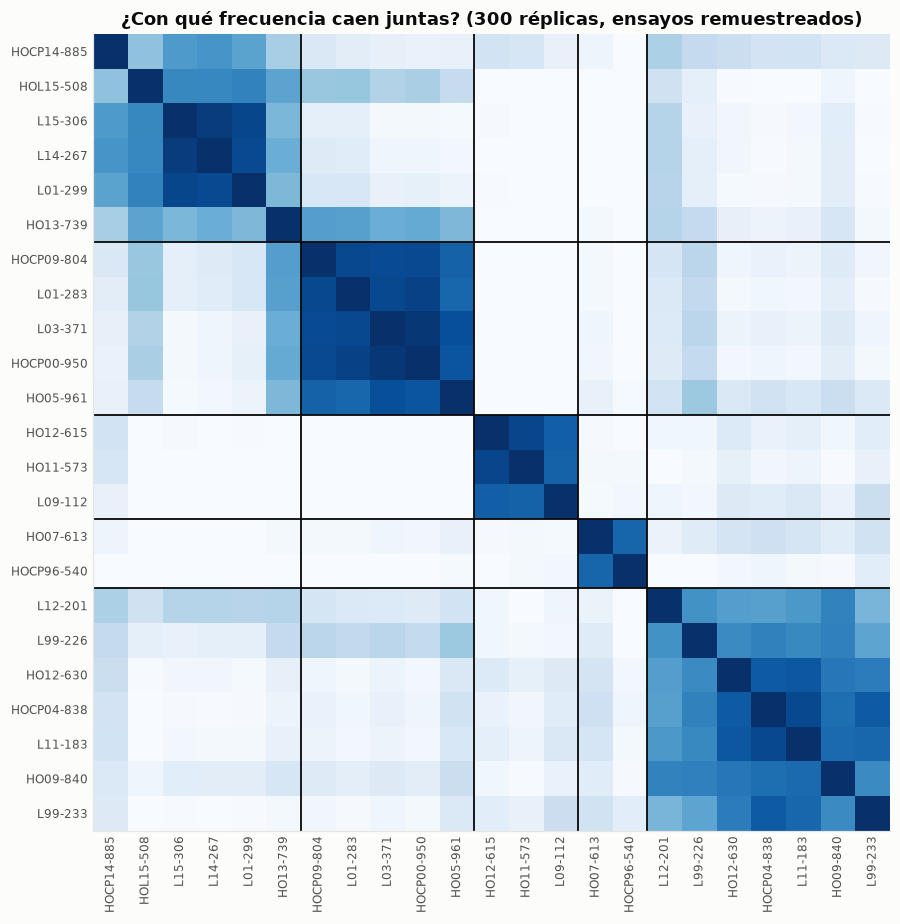

In [12]:
fig, ax = plt.subplots(figsize=(9.5, 8.5))
M = COA.loc[orden, orden].to_numpy()
ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n), orden, rotation=90, fontsize=8); ax.set_yticks(range(n), orden, fontsize=8)
ax.grid(False); ax.tick_params(length=0)
for i in range(1, n):
    if gr[i] != gr[i - 1]:
        ax.axhline(i - 0.5, color=TINTA, lw=1.2); ax.axvline(i - 0.5, color=TINTA, lw=1.2)
ax.set_title("¿Con qué frecuencia caen juntas? (300 réplicas, ensayos remuestreados)")
guardar(fig, "serie1_22_certeza_grupos.png")

**Lectura.** "Mucha caña" e "inestables" son grupos firmes (Jaccard ≥ 0.75). "Completas", "calidad sin caña" y "sin
ventaja clara" son patrones reales con bordes difusos (0.6-0.75). Las del borde tienen explicación:
- **HOCP14-885** es la única con mucha caña **y** mucha calidad; no se parece del todo a ningún grupo.
- **HO13-739 y HOL15-508** tienen la calidad de las completas pero poca caña: a veces caen con "calidad sin caña". Lo que
  las separa es la longevidad (HOL15-508 gana ~8 % por corte, aunque medida solo hasta soca 2).

Para una variedad del borde, la etiqueta importa menos que su resultado económico en la pregunta 1.

## 6. Validación externa: ¿los grupos significan algo en dinero?

La ganancia económica de la pregunta 1 **no** entró a formar los grupos. Si los grupos capturan algo real, deberían
separar la ganancia. Prueba de permutación: proporción de la variación de la ganancia entre grupos (η²) contra 10,000
asignaciones al azar con los mismos tamaños.

In [13]:
y = SEG["ganancia_p1"].to_numpy(); lab = SEG["grupo"].to_numpy()
def eta2(lab):
    m = y.mean(); return sum((lab == g).sum() * (y[lab == g].mean() - m) ** 2 for g in set(lab)) / ((y - m) ** 2).sum()
e_obs = eta2(lab)
rng = np.random.default_rng(SEED)
e_null = np.array([eta2(rng.permutation(lab)) for _ in range(10_000)])
print(f"η² = {e_obs:.2f} (los grupos explican {e_obs:.0%} de la variación de la ganancia); p = {np.mean(e_null >= e_obs):.4f}")
display(SEG.groupby("grupo")["ganancia_p1"].agg(["median", "min", "max", "count"]).loc[ORDEN_G].round(0))

η² = 0.74 (los grupos explican 74% de la variación de la ganancia); p = 0.0000


,median,min,max,count
grupo,,,,
"Completas: caña, calidad y longevidad",191.0,90.0,272.0,6
Calidad sin caña,8.0,-21.0,91.0,5
"Mucha caña, menos calidad",9.0,-55.0,124.0,3
Inestables y de vida corta,-115.0,-182.0,-47.0,2
Sin ventaja clara,-23.0,-86.0,46.0,7


## 7. Artefacto: asignar una variedad nueva a un grupo

In [14]:
SEG_OUT = SEG.loc[orden, ["grupo", "certeza"]].join(tabla).join(SEG[["ganancia_p1", "rank_p1", "ciclo_p1", "fibra_dif_pp", "fibra_parcelas"]])
SEG_OUT.round(3).to_csv(TAB / "serie1_segmentos.csv")
art = {"descripcion": "Serie I · P3. k-means sobre 4 indicadores estandarizados (log vs testigos núcleo). "
                      "Para una variedad nueva: calcular indicadores con campo_segmentos.indicadores, estandarizar con media/desvío y asignar al centro más cercano.",
       "indicadores": INDICADORES, "media": MU.to_dict(), "desvio": SD.to_dict(), "k": K,
       "centros_z": {NOMBRES[i]: dict(zip(INDICADORES, map(float, km.cluster_centers_[i]))) for i in range(K)},
       "reproducibilidad_ari": float(ESTAB.loc[K, "ARI_mediana"]), "jaccard": JAC.round(3).to_dict(),
       "variedades": SEG_OUT[["grupo", "certeza"]].round(3).to_dict("index")}
(MOD / "serie1_segmentos.json").write_text(json.dumps(art, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
# verificación: el centro más cercano reproduce la asignación de k-means
aj = json.loads((MOD / "serie1_segmentos.json").read_text(encoding="utf-8"))
cz = pd.DataFrame(aj["centros_z"]).T
zz = (X[INDICADORES] - pd.Series(aj["media"])) / pd.Series(aj["desvio"])
asig = zz.apply(lambda r: ((cz - r) ** 2).sum(axis=1).idxmin(), axis=1)
print(f"JSON reproduce {(asig == SEG['grupo']).mean():.0%} de las asignaciones")
resumen3 = {"silueta": SIL.round(4).reset_index(names="k").to_dict("records"),
            "estabilidad": ESTAB.drop(columns="tamaños").round(4).reset_index(names="k").to_dict("records"),
            "tamaños": {int(k): list(map(int, v)) for k, v in ESTAB["tamaños"].items()}, "k": int(K),
            "perfil": PERFIL.round(3).reset_index().to_dict("records"), "jaccard": JAC.round(3).to_dict(),
            "eta2": float(e_obs), "p_eta2": float(np.mean(e_null >= e_obs)),
            "correlaciones": X[INDICADORES].corr().round(3).to_dict(), "ruido_mediana": float(ruido.median()),
            "pca": (pca.explained_variance_ratio_ * 100).round(1).tolist(), "orden_grupos": ORDEN_G}
_ = (MOD / "serie1_resumen_p3.json").write_text(json.dumps(resumen3, indent=1, ensure_ascii=False, default=float), encoding="utf-8")

JSON reproduce 100% de las asignaciones


## 8. Evaluación gerencial

In [15]:
for g in ORDEN_G:
    m = SEG[SEG["grupo"] == g].sort_values("rank_p1"); pr = PERFIL.loc[g]
    print(f"■ {g} ({len(m)}): {', '.join(m.index)}")
    print(f"   caña {pr['caña %']:+.1f} % · TRS {pr['TRS %']:+.1f} % · azúcar plantía {pr['azúcar plantía %']:+.1f} % · "
          f"por corte {pr['caña por corte %']:+.1f} % · σ {pr['σ interacción %']:.1f} % · ganancia P1 mediana US${pr['ganancia P1 US$/acre/año (mediana)']:,.0f}"
          f" · Jaccard {JAC[g]:.2f}")

■ Completas: caña, calidad y longevidad (6): HOCP14-885, HOL15-508, L15-306, L14-267, L01-299, HO13-739
   caña +1.7 % · TRS +5.6 % · azúcar plantía +7.5 % · por corte +5.0 % · σ 5.4 % · ganancia P1 mediana US$191 · Jaccard 0.70
■ Calidad sin caña (5): HOCP09-804, L01-283, L03-371, HOCP00-950, HO05-961
   caña -4.7 % · TRS +5.1 % · azúcar plantía +0.1 % · por corte +0.7 % · σ 9.5 % · ganancia P1 mediana US$8 · Jaccard 0.73
■ Mucha caña, menos calidad (3): HO12-615, HO11-573, L09-112
   caña +12.0 % · TRS -3.7 % · azúcar plantía +7.9 % · por corte -3.3 % · σ 5.7 % · ganancia P1 mediana US$9 · Jaccard 0.84
■ Inestables y de vida corta (2): HO07-613, HOCP96-540
   caña +1.4 % · TRS -0.9 % · azúcar plantía +0.6 % · por corte -8.9 % · σ 17.2 % · ganancia P1 mediana US$-115 · Jaccard 0.85
■ Sin ventaja clara (7): L12-201, L99-226, HO12-630, HOCP04-838, L11-183, HO09-840, L99-233
   caña +0.7 % · TRS +0.3 % · azúcar plantía +1.0 % · por corte -1.8 % · σ 6.9 % · ganancia P1 mediana US$-23 · Ja

**Qué significa para el ingenio.** Las variedades no se dividen en tipos naturales: hay un **compromiso entre
tonelaje y calidad**; la calidad viene con longevidad (r = 0.48) y la longevidad con estabilidad (r = 0.58). Los grupos son perfiles útiles para
gestionar el portafolio, y separan bien el dinero: aunque se formaron sin mirar la economía, explican la mayor parte de
la diferencia de ganancia de la pregunta 1.

**Qué representa cada grupo y qué hacer con él** (cifras en la celda anterior):
- **Completas: caña, calidad y longevidad.** Las ganadoras de la pregunta 1: ~5 % más TRS que los testigos y ganan
  ~5 % por corte, así que la ventaja crece en las socas. Ciclo óptimo de 4 cortes (5 para L01-299). *Decisión:* núcleo
  de la expansión.
- **Calidad sin caña.** Buen TRS pero ~5 % menos caña: el azúcar por acre queda igual que los testigos, y además son
  menos estables. Son variedades con muchos años en evaluación. *Decisión:* no ampliar; su valor depende de cómo se
  pague la caña (si el esquema premia la calidad).
- **Mucha caña, menos calidad.** En plantía dan tanto azúcar como las completas (+8 %), pero pierden ~3 % por corte
  frente a los testigos: la ventaja se va en las socas. *Decisión:* no son base de expansión; HO12-615 es la excepción
  del grupo (casi no pierde por corte). Si su fibra alta se confirma (solo HO12-615 tiene fibra comparable contra los testigos), son candidatas
  para lotes donde importe el bagazo para cogenerar.
- **Inestables y de vida corta.** Su ventaja varía 2-3 veces más que la del resto y pierden ~9 % por corte; ciclo
  óptimo de 3 cortes. Incluye a HOCP96-540, un testigo núcleo. *Decisión:* retirar de la expansión y evaluar
  reemplazarla como testigo: un testigo inestable vuelve ruidosa toda comparación (pregunta 4).
- **Sin ventaja clara.** Cerca de los testigos en todo; incluye a HOCP04-838, otro testigo núcleo. *Decisión:* no
  ampliar.

**Impacto estimado.** La diferencia de ganancia entre grupos es de cientos de US$/acre/año (ver la celda de validación
externa). El valor del análisis no es una cifra nueva: es una regla para clasificar cada variedad nueva con 4 números
y saber qué rol darle antes de que acumule 3-4 años de margen.

**Riesgos.**
- *Continuo, no tipos:* las variedades del borde cambian de grupo al remuestrear (ver certeza). Entre ellas están
  HOCP14-885 y HOL15-508, las dos primeras de la pregunta 1. HOCP14-885 es la única que combina mucha caña y mucha
  calidad, así que no tiene un grupo firme. Para las del borde, decidir con la pregunta 1, no con la etiqueta.
- *Estabilidad de las nuevas:* se midió con 2-4 años; las de 10-12 años tuvieron más oportunidad de mostrar
  inestabilidad. La estabilidad de las nuevas puede estar sobreestimada.
- *Fibra:* sin datos para 7 de las 23 y escasa en 2020-2021; el rol de "caña para cogeneración" necesita medirla.
- *Validez externa:* son variedades de Louisiana. Lo que se traslada al ingenio es el método (4 indicadores contra
  testigos + grupos reproducibles), no las variedades.

**Nivel de certeza.** Alta en el compromiso caña-calidad y en que los grupos separan la ganancia (prueba de
permutación). Media en las fronteras: el número de grupos se eligió por reproducibilidad y varias variedades del borde
tienen asignación dudosa.